<a href="https://colab.research.google.com/github/Innej3/SignalPropagation-/blob/main/Replication_Paper_Spational_Temporal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
Replication of paper: Predicting the patterns of spatio-temporal signal propagation
Link: https://arxiv.org/pdf/1801.08854

"""

In [ ]:
'''
TOpology alone doesnt tell us how a system behaves the same graph running different
dynamics spreads signials completely differently or you can say that nodes interact
through non linear dynamic mechanism. Two signals with the exact same wiring
can propagate signals in completely different ways.

Historically it has been the case that network path length (number of steps between nodes)
is the primary predictor of how fast a signal or contagion spreads.
However in reality theses assumptions do not hold.

The Question paper tring to answer? if a poke a node j when does node i feel it?

'''

In [ ]:
'''
The systems start at a steady state. The authors apply a permanent perturbation
$\delta{x_j}$ to a single soruce protein j and watch the singal propagation to other
all target nodes i=1,...., N
'''

In [ ]:
'''
dx_i/dt = M₀(x_i) + Σ_j A_ij M₁(x_i) M₂(x_j)
M₀: what node i does alone (decay, growth).
M₁(x_i): how i’s own state gates incoming influence.
M₂(x_j): what neighbour j sends.

$\tau_i ~ S_i^\theta$

$\tau_i - local response time

S_i = $\sum_j A_{ij}$, degree of node i

And $\theta$ value dependns on the dynamics. FOR SIS its -1, R_2 is 3/2 and R_1 is 0
'''

In [ ]:
'''
Experiment

let the system settle to a steady state, then perturb. And observe how long it
takes for effect to move across
'''

In [5]:
import numpy as np
import networkx as nx
from scipy.integrate import solve_ivp
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

In [6]:
N = 350               # Nodes per network
AVG_DEG = 4           # Average degree <k> = 4
ALPHA = 0.1           # 10% perturbation
ETA = 0.7             # Threshold eta = 0.7
NUM_SOURCES = 20      # Perturbed source nodes per model
SEED = 42
np.random.seed(SEED)

In [7]:
def build_er_and_sf(n, avg_k):
  G_er = nx.erdos_renyi_graph(n, p=avg_k/(n-1), seed=SEED)
  largest_cc = max(nx.connected_components(G_er), key=len)
  G_er = nx.convert_node_labels_to_integers(G_er.subgraph(largest_cc))
  A_er = nx.to_scipy_sparse_array(G_er, dtype=float, format='csr')

  G_sf = nx.barabasi_albert_graph(n, m=avg_k//2, seed=SEED)
  A_sf = nx.to_scipy_sparse_array(G_sf, dtype=float, format='csr')
  return {'ER': (A_er, G_er), 'SF': (A_sf, G_sf)}

In [8]:
def find_steady_state_model(A, model_type, freeze_idx=None, freeze_val=None):
  """
  Finds steady state dx_i/dt = 0 algebraically via fixed-point iteration:
  - R1 (a=1, h=1):   x_i = [sum A_ij x_j/(1+x_j)]
  - R2 (a=0.4, h=0.2): x_i = [sum A_ij x_j^0.2/(1+x_j^0.2)]^(1/0.4)
  - E  (SIS):        x_i = (A x)_i / (1 + (A x)_i)
  """
  n = A.shape[0]
  x = np.full(n, 1.5)
  if freeze_idx is not None:
    x[freeze_idx] = freeze_val

  for _ in range(8000):
    if model_type == 'R1':
      H = x / (1.0 + x)
      x_next = A.dot(H)
    elif model_type == 'R2':
      H = (x ** 0.2) / (1.0 + (x ** 0.2))
      x_next = (A.dot(H)) ** (1.0 / 0.4)
    elif model_type == 'E':
      Ax = A.dot(x)
      x_next = Ax / (1.0 + Ax)
    if freeze_idx is not None:
      x_next[freeze_idx] = freeze_val
    if np.max(np.abs(x_next - x) / (x_next + 1e-15)) < 1e-13:
      break
    # Damped update for smooth convergence on stiff power laws
    x = 0.5 * x + 0.5 * x_next
  return x


In [9]:
def simulate_perturbation(A, x_ss, source_j, model_type, alpha=0.1, eta=0.7):
  n = A.shape[0]
  perturbed_val = x_ss[source_j] * (1.0 + alpha)
  x_inf = find_steady_state_model(A, model_type, freeze_idx=source_j, freeze_val=perturbed_val)
  delta_x_inf = x_inf - x_ss

  y0 = x_ss.copy()
  y0[source_j] = perturbed_val

  # Time horizon depends strongly on universality class (Page 3 & Fig. 3):
  # E takes t ~ 3, R1 takes t ~ 15, R2 (hub bottleneck!) takes t ~ 5000
  if model_type == 'R1':
    t_max = 18.0
    t_eval = np.linspace(0.01, t_max, 700)
    method = 'RK45'
  elif model_type == 'R2':
    t_max = 6000.0
    t_eval = np.geomspace(1e-1, t_max, 700)
    method = 'Radau'  # Implicit solver handles stiff 4-order-of-magnitude timescales cleanly
  elif model_type == 'E':
    t_max = 12.0
    t_eval = np.geomspace(1e-3, t_max, 600)
    method = 'RK45'
  def ode_rhs(t, x):
    x_pos = np.maximum(x, 1e-15)
    if model_type == 'R1':
      dx = -x_pos + A.dot(x_pos / (1.0 + x_pos))
    elif model_type == 'R2':
      xh = x_pos ** 0.2
      dx = -(x_pos ** 0.4) + A.dot(xh / (1.0 + xh))
    elif model_type == 'E':
      dx = -x_pos + (1.0 - x_pos) * A.dot(x_pos)
    dx[source_j] = 0.0
    return dx
  sol = solve_ivp(ode_rhs, [0.0, t_max], y0, method=method, t_eval=t_eval, rtol=1e-7, atol=1e-9)

  T_ji = np.full(n, np.nan)
  for i in range(n):
    if i == source_j or delta_x_inf[i] <= 1e-11:
      continue
    f_i = (sol.y[i, :] - x_ss[i]) / delta_x_inf[i]
    idx = int(np.argmax(f_i >= eta))
    if idx > 0 and f_i[idx] >= eta:
      t0, t1 = t_eval[idx - 1], t_eval[idx]
      f0, f1 = f_i[idx - 1], f_i[idx]
      T_ji[i] = t0 + (eta - f0) * (t1 - t0) / (f1 - f0 + 1e-15)
  return T_ji

In [10]:
def log_binning(S, tau, num_bins=11):
  valid = (~np.isnan(tau)) & (tau > 0) & (S > 0)
  Sv, tv = S[valid], tau[valid]
  bins = np.geomspace(Sv.min() * 0.99, Sv.max() * 1.01, num_bins + 1)
  Sb, tb = [], []
  for k in range(num_bins):
    m = (Sv > bins[k]) & (Sv <= bins[k+1])
    if np.sum(m) > 0:
      Sb.append(np.mean(Sv[m]))
      tb.append(np.mean(tv[m]))
  return np.array(Sb), np.array(tb)

In [11]:
topologies = build_er_and_sf(N, AVG_DEG)
models = ['R1', 'R2', 'E']
data = {m: {} for m in models}

In [12]:
for m in models:
  for net_name, (A, G) in topologies.items():
    print(f"Simulating Model {m} on {net_name}...")
    n_nodes = A.shape[0]
    S = np.array(A.sum(axis=1)).flatten()
    x_ss = find_steady_state_model(A, m)

    sources = np.random.choice(n_nodes, size=NUM_SOURCES, replace=False)
    T_dict = {}
    local_times = [[] for _ in range(n_nodes)]

    for j in sources:
      T_ji = simulate_perturbation(A, x_ss, j, m, ALPHA, ETA)
      T_dict[j] = T_ji
      nbrs = A.indices[A.indptr[j]:A.indptr[j+1]]
      for i in nbrs:
        if not np.isnan(T_ji[i]):
          local_times[i].append(T_ji[i])

    tau_i = np.array([np.mean(t_list) if len(t_list) > 0 else np.nan for t_list in local_times])
    data[m][net_name] = {'S': S, 'tau': tau_i, 'T_dict': T_dict, 'G': G}

Simulating Model R1 on ER...
Simulating Model R1 on SF...
Simulating Model R2 on ER...
Simulating Model R2 on SF...
Simulating Model E on ER...
Simulating Model E on SF...


In [13]:
from collections import deque

def compute_temporal_distance(G, S, source_j, theta):
    """L(j->i) = min over hop-shortest paths of sum_{p on path, p != j} S_p^theta  (Eq. 5)."""
    n = len(S)
    w = S ** theta
    hops = np.full(n, np.inf); L = np.full(n, np.inf)
    hops[source_j] = 0; L[source_j] = 0.0
    q = deque([source_j])
    while q:
        u = q.popleft()
        for v in G.neighbors(u):
            if hops[v] == np.inf:
                hops[v] = hops[u] + 1; L[v] = L[u] + w[v]; q.append(v)
            elif hops[v] == hops[u] + 1 and L[u] + w[v] < L[v]:
                L[v] = L[u] + w[v]
    L[source_j] = np.nan; hops[source_j] = np.nan
    return L, hops

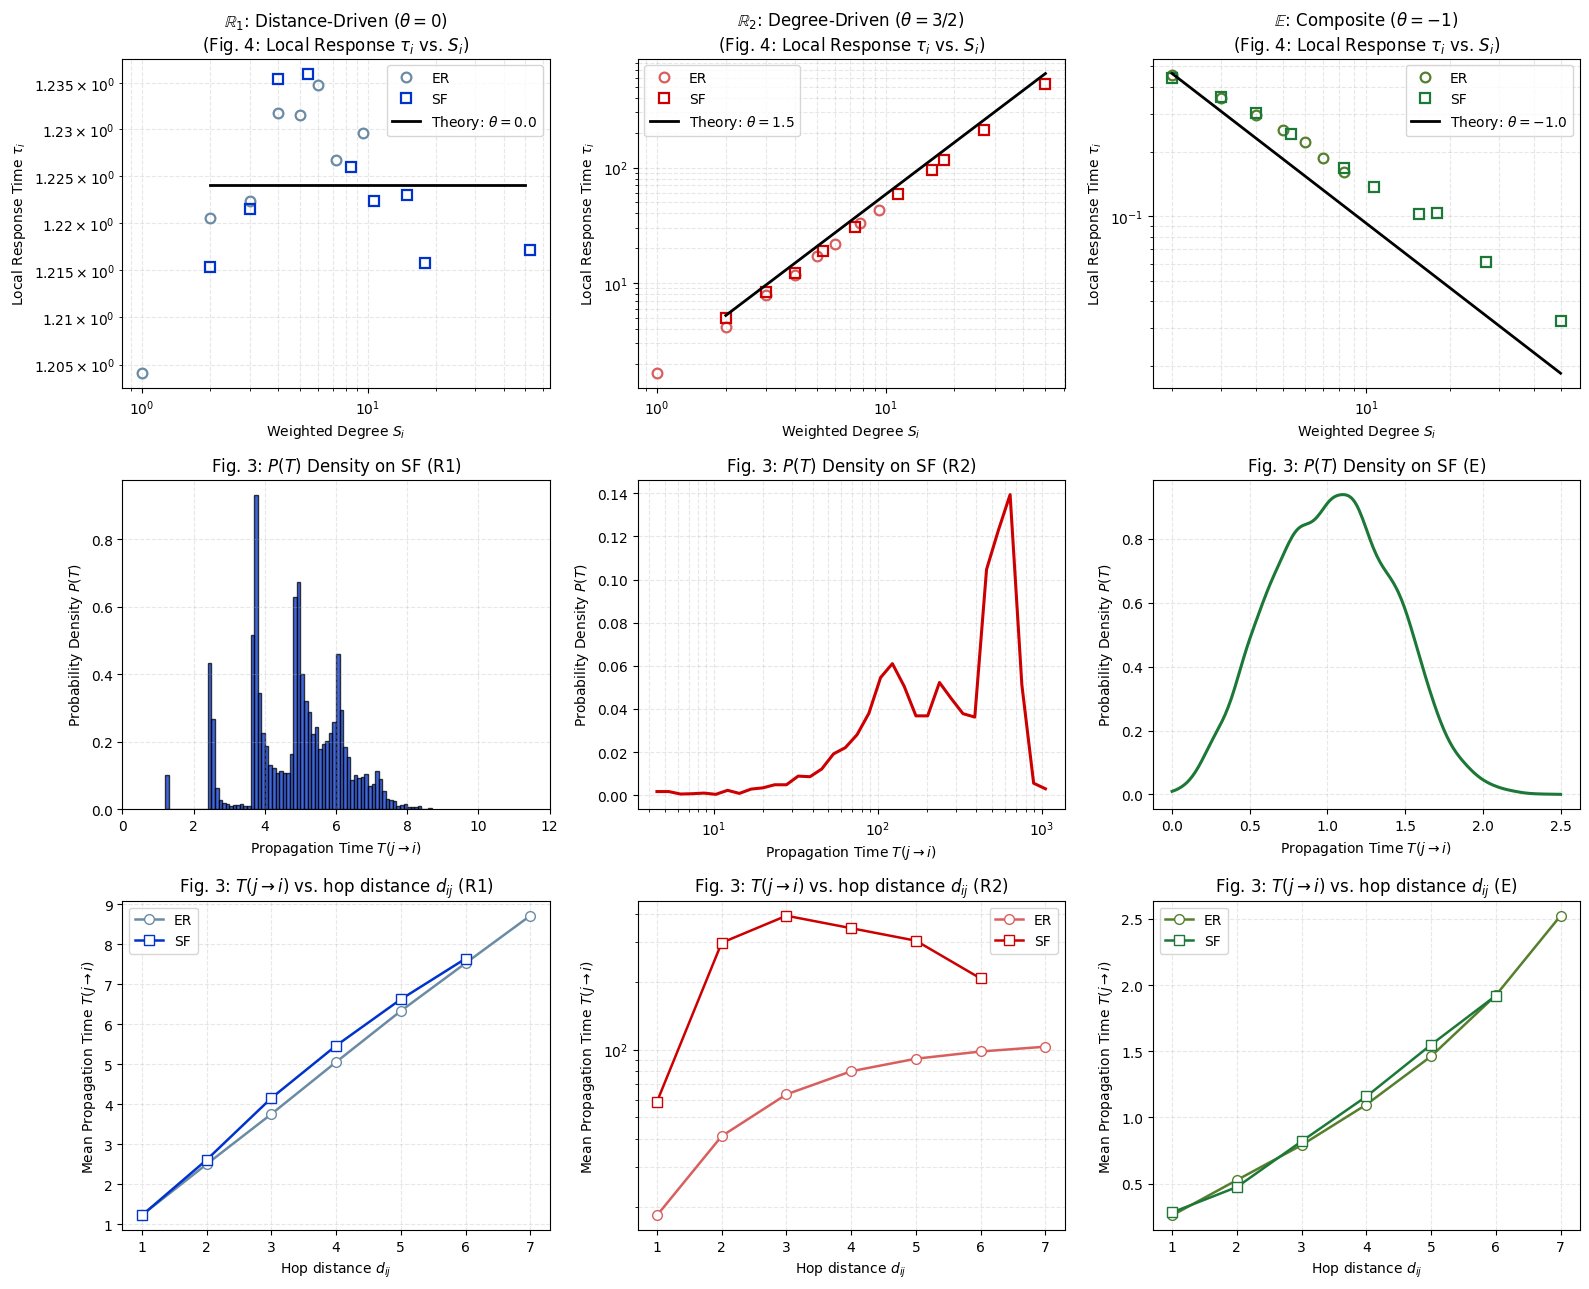

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(16, 13))

colors = {
    'R1': {'ER': '#6b8ba4', 'SF': '#0033cc'},
    'R2': {'ER': '#d95f5f', 'SF': '#cc0000'},
    'E':  {'ER': '#557f2d', 'SF': '#1b7837'}
}
titles = {
    'R1': r'$\mathbb{R}_1$: Distance-Driven ($\theta = 0$)',
    'R2': r'$\mathbb{R}_2$: Degree-Driven ($\theta = 3/2$)',
    'E':  r'$\mathbb{E}$: Composite ($\theta = -1$)'
}
thetas = {'R1': 0.0, 'R2': 1.5, 'E': -1.0}

for col, m in enumerate(models):
    # --- ROW 0: Local Response Time tau_i vs S_i (Fig. 4a, 4c, 4f) ---
    ax = axes[0, col]
    for net_name, marker in [('ER', 'o'), ('SF', 's')]:
        Sb, tb = log_binning(data[m][net_name]['S'], data[m][net_name]['tau'])
        ax.loglog(Sb, tb, marker=marker, linestyle='None', markersize=7,
                  markerfacecolor='none', markeredgewidth=1.6,
                  color=colors[m][net_name], label=net_name)

    s_ref = np.geomspace(2, 50, 40)
    tau_mid = np.nanmedian(data[m]['SF']['tau'])
    s_mid = np.median(data[m]['SF']['S'])
    c_scale = tau_mid / (s_mid ** thetas[m])
    ax.loglog(s_ref, c_scale * (s_ref ** thetas[m]), 'k-', lw=2, label=rf'Theory: $\theta={thetas[m]}$')
    ax.set_title(titles[m] + '\n(Fig. 4: Local Response $\\tau_i$ vs. $S_i$)', fontsize=12)
    ax.set_xlabel(r'Weighted Degree $S_i$')
    ax.set_ylabel(r'Local Response Time $\tau_i$')
    ax.legend()
    ax.grid(True, which="both", ls="--", alpha=0.3)

    # --- ROW 1: P(T) Distribution on SF Network (Fig. 3g, 3i, 3l) ---
    ax = axes[1, col]
    T_all_sf = []
    for j, T_ji in data[m]['SF']['T_dict'].items():
        valid_T = T_ji[~np.isnan(T_ji)]
        T_all_sf.extend(valid_T)
    T_all_sf = np.array(T_all_sf)

    if m == 'R1':
        # Sharp discrete peaks for each shell L_ij = 1, 2, 3...
        ax.hist(T_all_sf, bins=75, density=True, color=colors[m]['SF'], alpha=0.75, edgecolor='black', lw=0.4)
        ax.set_xlim(0, 12)
    elif m == 'R2':
        # Log-spaced broad distribution spanning orders of magnitude
        log_bins = np.geomspace(max(T_all_sf.min(), 1.0), T_all_sf.max(), 35)
        counts, edges = np.histogram(T_all_sf, bins=log_bins, density=False)
        centers = np.sqrt(edges[:-1] * edges[1:])
        ax.plot(centers, counts / len(T_all_sf), color=colors[m]['SF'], lw=2.2)
        ax.set_xscale('log')
    elif m == 'E':
        t_grid = np.linspace(0, 2.5, 250)
        kde = gaussian_kde(T_all_sf)
        ax.plot(t_grid, kde(t_grid), color=colors[m]['SF'], lw=2.2)

    ax.set_title(f'Fig. 3: $P(T)$ Density on SF ({m})', fontsize=12)
    ax.set_xlabel(r'Propagation Time $T(j \rightarrow i)$')
    ax.set_ylabel(r'Probability Density $P(T)$')
    ax.grid(True, which="both", ls="--", alpha=0.3)

    # --- ROW 2: T(j -> i) vs Shortest Path Distance L_ij (Fig. 3m, 3o, 3r) ---
    ax = axes[2, col]
    for net_name, marker in [('ER', 'o'), ('SF', 's')]:
        G = data[m][net_name]['G']
        dist_buckets = {}
        for j, T_ji in data[m][net_name]['T_dict'].items():
            lengths = nx.single_source_shortest_path_length(G, j)
            for i, d in lengths.items():
                if d >= 1 and not np.isnan(T_ji[i]):
                    dist_buckets.setdefault(d, []).append(T_ji[i])
        dists = sorted([d for d in dist_buckets if len(dist_buckets[d]) > 10 and d <= 7])
        mean_T = [np.mean(dist_buckets[d]) for d in dists]
        ax.plot(dists, mean_T, marker=marker, lw=1.8, color=colors[m][net_name],
                markerfacecolor='white', markersize=7, label=net_name)
    if m == 'R2':
        ax.set_yscale('log')
    ax.set_title(f'Fig. 3: $T(j \\rightarrow i)$ vs. hop distance $d_{{ij}}$ ({m})', fontsize=12)
    ax.set_xlabel(r'Hop distance $d_{ij}$')
    ax.set_ylabel(r'Mean Propagation Time $T(j \rightarrow i)$')
    ax.legend()
    ax.grid(True, which="both", ls="--", alpha=0.3)

plt.tight_layout()
plt.show()

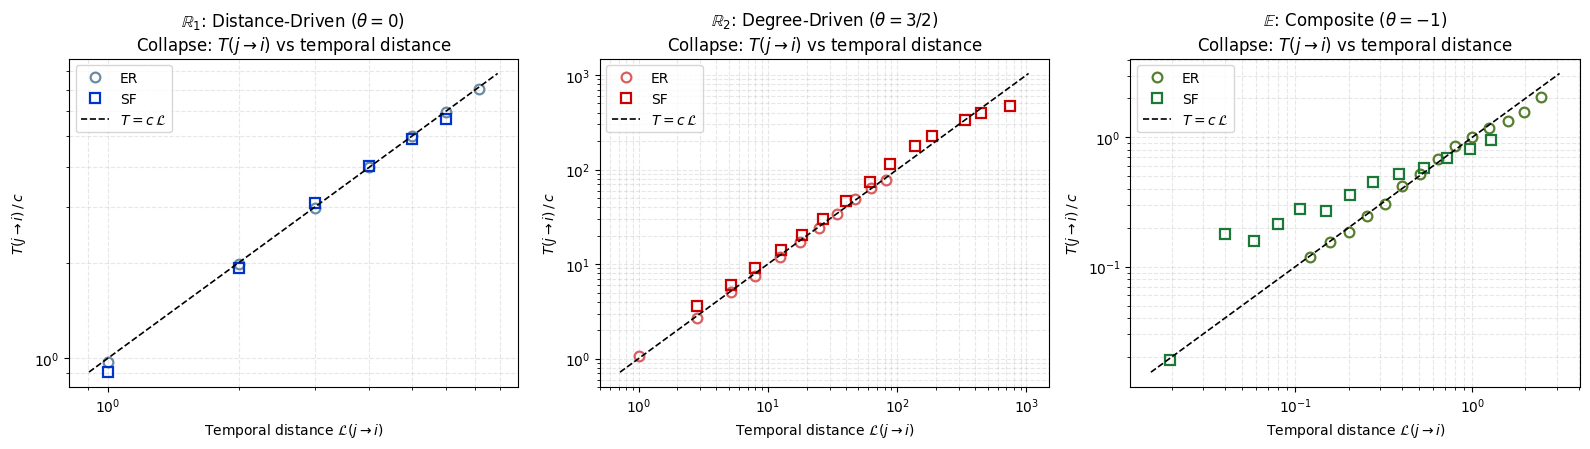

In [17]:
thetas = {'R1': 0.0, 'R2': 1.5, 'E': -1.0}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for col, m in enumerate(models):
    ax = axes[col]
    for net, marker in [('ER', 'o'), ('SF', 's')]:
        d = data[m][net]; Ls, Ts = [], []
        for j, T_ji in d['T_dict'].items():
            L, _ = compute_temporal_distance(d['G'], d['S'], j, thetas[m])
            ok = np.isfinite(T_ji) & np.isfinite(L) & (T_ji > 0) & (L > 0)
            Ls.append(L[ok]); Ts.append(T_ji[ok])
        L, T = np.concatenate(Ls), np.concatenate(Ts)
        c = np.exp(np.mean(np.log(T / L)))            # T ~ c*L: fit only the prefactor
        Lb, Tb = log_binning(L, T / c, num_bins=14)
        ax.loglog(Lb, Tb, marker, ms=7, mfc='none', mew=1.6, color=colors[m][net], label=net)
    lo, hi = ax.get_xlim()
    ax.loglog([lo, hi], [lo, hi], 'k--', lw=1.2, label=r'$T = c\,\mathcal{L}$')
    ax.set_title(titles[m] + '\n' + r'Collapse: $T(j\to i)$ vs temporal distance', fontsize=12)
    ax.set_xlabel(r'Temporal distance $\mathcal{L}(j\to i)$')
    ax.set_ylabel(r'$T(j\to i)\,/\,c$')
    ax.legend(); ax.grid(True, which='both', ls='--', alpha=0.3)
plt.tight_layout(); plt.show()

In [19]:
print(f"{'model':5s} {'net':4s} {'corr(logT, log L)':>18s} {'corr(logT, log hops)':>21s}")
for m in models:
    for net in ['ER', 'SF']:
        d = data[m][net]; cL, cH = [], []
        for j, T_ji in d['T_dict'].items():
            L, hops = compute_temporal_distance(d['G'], d['S'], j, thetas[m])
            ok = np.isfinite(T_ji) & np.isfinite(L) & (T_ji > 0)
            cL.append(np.corrcoef(np.log(T_ji[ok]), np.log(L[ok]))[0, 1])
            cH.append(np.corrcoef(np.log(T_ji[ok]), np.log(hops[ok]))[0, 1])
        print(f"{m:5s} {net:4s} {np.mean(cL):18.2f} {np.mean(cH):21.2f}")

model net   corr(logT, log L)  corr(logT, log hops)
R1    ER                 0.99                  0.99
R1    SF                 0.94                  0.94
R2    ER                 0.98                  0.74
R2    SF                 0.91                  0.25
E     ER                 0.92                  0.93
E     SF                 0.63                  0.80


In [20]:
for net in ['ER', 'SF']:
    A, G = topologies[net]
    d = data['E'][net]
    x_ss = find_steady_state_model(A, 'E')
    J = 1.0 + A.dot(x_ss)
    c_S, c_J, c_H = [], [], []
    for j, T_ji in d['T_dict'].items():
        L_S, hops = compute_temporal_distance(G, d['S'], j, -1.0)
        L_J, _ = compute_temporal_distance(G, J, j, -1.0)
        ok = np.isfinite(T_ji) & np.isfinite(L_S) & (T_ji > 0)
        lt = np.log(T_ji[ok])
        c_S.append(np.corrcoef(lt, np.log(L_S[ok]))[0, 1])
        c_J.append(np.corrcoef(lt, np.log(L_J[ok]))[0, 1])
        c_H.append(np.corrcoef(lt, np.log(hops[ok]))[0, 1])
    print(f"E on {net}: L with S^-1 = {np.mean(c_S):.2f} | L with exact 1/J = {np.mean(c_J):.2f} | hops = {np.mean(c_H):.2f}"
          f" | x* range {x_ss.min():.2f}-{x_ss.max():.2f}")

E on ER: L with S^-1 = 0.92 | L with exact 1/J = 0.95 | hops = 0.93 | x* range 0.34-0.89
E on SF: L with S^-1 = 0.63 | L with exact 1/J = 0.69 | hops = 0.80 | x* range 0.58-0.98
